# Unit 2, Lecture 2: Fourier Transform and FFT
## From a Sampled Time Series to its Linear Spectrum
**Course:** Data-Driven Modelling for Mechanical Systems (NMED 5XX)  
**Reference Material:** 
- Lecture 2 Slides (`Lec_2.pdf`)
- Steven L. Brunton & J. Nathan Kutz, *Data-Driven Science and Engineering*, Chapter 2 (Fourier & Wavelet Transforms)
- Lloyd N. Trefethen & David Bau, *Numerical Linear Algebra*, Lecture 24

---

### Key Learning Objectives
1. **From Continuous Integral to Computable Sum:** Understand the exact transition from the continuous Fourier transform $\mathcal{F}\{x(t)\}$ to the Discrete Fourier Transform (DFT), explicitly accounting for sampling interval $\Delta t$ and record length $T = N\Delta t$.
2. **Correct Physical Units & Scaling:** Distinguish between the raw algorithm output (`np.fft.fft`) and the true physical **linear spectrum** $X_m = \text{fft}(x_n) \cdot \Delta t$ with units $[x]/\text{Hz}$ (e.g. $\text{Pa/Hz}$).
3. **Hermitian Symmetry & Negative Frequencies:** Characterize the symmetry of spectra for real-valued time series ($X_{N/2+p} = X_{N/2-p}^*$), identifying the $N/2 + 1$ unique spectral values.
4. **Exact Inverse Reconstruction:** Recover the original continuous physical amplitudes using $x_n = \text{ifft}(X_m) / \Delta t$.
5. **Sampling Limitations:** Quantify and observe spectral leakage (non-integer period windows), aliasing (frequencies above the Nyquist rate $f_s/2$), and the time-frequency resolution trade-off ($\Delta f = 1/T$).
6. **Data-Driven Synthesis:** Synthesize stochastic time series (white and pink noise) with targeted spectral profiles and random phases while maintaining strict reality constraints.
7. **Numerical Self-Checks:** Reproduce all numbers, analytical hand-calculations, and worked exercises presented in the lecture deck.

---
## 1. Setup, Discrete Bookkeeping, and The Sound Pressure Puzzle (Slides 3, 6–9, 11–12)

### The Puzzle
Consider a sound pressure signal sampled at $f_s = 1000$ samples/s with $N = 8$ samples:
$$x_n = [-4, -9, -6, 1, 1, -3, 6, -2] \text{ Pa}$$
A colleague runs `fft(xn)`, observes $-16$ at index $0$ ($f = 0$), and concludes that the mean pressure is $-16$ Pa.
- **Why is this incorrect?** The raw discrete Fourier sum evaluates $\sum_{n=0}^{N-1} x_n = -16$ Pa.
- **What is the true linear spectrum value at $f=0$?**
  $$X_0 = \sum_{n=0}^{N-1} x_n \Delta t = T \times \text{mean} = 0.008 \text{ s} \times (-2 \text{ Pa}) = -0.016 \text{ Pa/Hz}$$
  *(Answer C from Slide 3).*
- The mean pressure is recovered by $\text{mean} = X_0 / T = -2.0$ Pa.

1 | Discrete Bookkeeping & Sound Pressure Puzzle
Sample count N       : 8
Sampling interval dt : 1.0 ms  (fs = 1000 Hz)
Record duration T    : 8.0 ms  (last sample at 7.0 ms)
Frequency spacing df : 125.0 Hz (Nyquist = 500.0 Hz)
Sample Mean          : -2.00 Pa (Sum = -16.0 Pa)
Mean Square Pressure : 23.00 Pa^2

By-Hand Calculation:
  X0 (f = 0 Hz)   = -0.0160 Pa/Hz  (Raw sum = -16.0 Pa)
  X4 (f = 500 Hz) = +0.0100 Pa/Hz


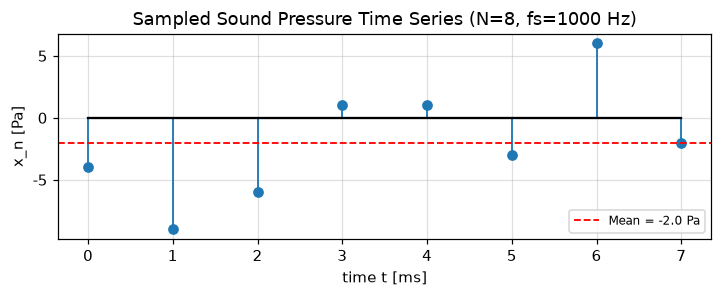

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Global styling matching lecture slide aesthetics
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.4,
    "axes.unicode_minus": False,
    "font.size": 10,
    "figure.figsize": (7, 3.2),
    "savefig.bbox": "tight"
})

# Parameters from Slide 3 & 9
fs = 1000.0                       # Sampling rate [Hz]
dt = 1.0 / fs                     # Sampling interval [s] = 0.001 s (1 ms)
xn = np.array([-4, -9, -6, 1, 1, -3, 6, -2], dtype=float)  # Sound pressure [Pa]
N = len(xn)                       # N = 8 samples
T = N * dt                        # Record duration [s] = 0.008 s (8 ms)
df = 1.0 / T                      # Frequency bin resolution [Hz] = 125 Hz
time_vec = np.arange(N) * dt      # Time stamps: 0, 1, ..., 7 ms
fm = np.arange(N) * df            # Frequency bins: 0, 125, ..., 875 Hz

# Statistical properties
mean_val = np.mean(xn)
mean_sq = np.mean(xn**2)

print("=" * 68)
print("1 | Discrete Bookkeeping & Sound Pressure Puzzle")
print("=" * 68)
print(f"Sample count N       : {N}")
print(f"Sampling interval dt : {dt*1e3:.1f} ms  (fs = {fs:.0f} Hz)")
print(f"Record duration T    : {T*1e3:.1f} ms  (last sample at {(N-1)*dt*1e3:.1f} ms)")
print(f"Frequency spacing df : {df:.1f} Hz (Nyquist = {fs/2:.1f} Hz)")
print(f"Sample Mean          : {mean_val:.2f} Pa (Sum = {np.sum(xn):.1f} Pa)")
print(f"Mean Square Pressure : {mean_sq:.2f} Pa^2")

# By-hand calculation (Slide 11)
X0_by_hand = np.sum(xn) * dt
# At m = N/2 = 4 (Nyquist frequency 500 Hz), kernel is e^{-i 2pi (4) n / 8} = e^{-i pi n} = (-1)^n
alt_signs = np.array([(-1)**n for n in range(N)])
X4_by_hand = np.sum(xn * alt_signs) * dt

print(f"\nBy-Hand Calculation:")
print(f"  X0 (f = 0 Hz)   = {X0_by_hand:.4f} Pa/Hz  (Raw sum = {np.sum(xn):.1f} Pa)")
print(f"  X4 (f = 500 Hz) = {X4_by_hand:+.4f} Pa/Hz")

# Visualize the discrete sound pressure series
fig, ax = plt.subplots(figsize=(6.8, 2.8))
markerline, stemlines, baseline = ax.stem(time_vec * 1e3, xn, basefmt="k-")
plt.setp(markerline, markersize=6, color="#1f77b4")
plt.setp(stemlines, color="#1f77b4", linewidth=1.2)
ax.axhline(mean_val, color="red", linestyle="--", linewidth=1.2, label=f"Mean = {mean_val:.1f} Pa")
ax.set(xlabel="time t [ms]", ylabel="x_n [Pa]", title="Sampled Sound Pressure Time Series (N=8, fs=1000 Hz)")
ax.set_xticks(time_vec * 1e3)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

---
## 2. Computing the Full Linear Spectrum and Hermitian Symmetry (Slides 13–15)

### Continuous Fourier Integral to Linear Spectrum
$$X(f) = \int_{-\infty}^\infty x(t) e^{-i 2\pi f t} dt \quad \longrightarrow \quad X_m = \sum_{n=0}^{N-1} x_n e^{-i 2\pi n m / N} \Delta t = \text{fft}(x_n) \cdot \Delta t$$

### Hermitian Symmetry for Real-Valued Data
For real $x_n$, negative frequencies satisfy $X_{-m} = X_m^*$.  
Due to periodicity $X_{m+N} = X_m$, for any offset $p$ from the Nyquist bin $N/2$:
$$X_{N/2 + p} = X_{N/2 - p}^*$$
- For $N=8$, Nyquist is at bin $m=4$ ($500$ Hz).
- $X_0$ and $X_{N/2}$ are strictly **real-valued**.
- Bins $5, 6, 7$ correspond to negative frequencies:
  $$625 \text{ Hz} \leftrightarrow -375 \text{ Hz}, \quad 750 \text{ Hz} \leftrightarrow -250 \text{ Hz}, \quad 875 \text{ Hz} \leftrightarrow -125 \text{ Hz}$$

2 | Full Linear Spectrum Table (Slide 13)
 m   f [Hz]   Equiv. f     Re [Pa/Hz]     Im [Pa/Hz]    Re [mPa/Hz]    Im [mPa/Hz]
------------------------------------------------------------------------
 0      0.0        0.0       -0.01600        0.00000         -16.00           0.00
 1    125.0      125.0       -0.01136        0.01412         -11.36          14.12
 2    250.0      250.0       -0.00300        0.01100          -3.00          11.00
 3    375.0      375.0        0.00136       -0.00988           1.36          -9.88
 4    500.0      500.0        0.01000        0.00000          10.00           0.00
 5    625.0     -375.0        0.00136        0.00988           1.36           9.88
 6    750.0     -250.0       -0.00300       -0.01100          -3.00         -11.00
 7    875.0     -125.0       -0.01136       -0.01412         -11.36         -14.12

Symmetry Verification (X[N/2 + p] == conj(X[N/2 - p])):
  p=1: |X_5 - X*_3| = 0.00e+00 (f = 625 Hz <-> 375 Hz)
  p=2: |X_6 - X*_2| = 0.00

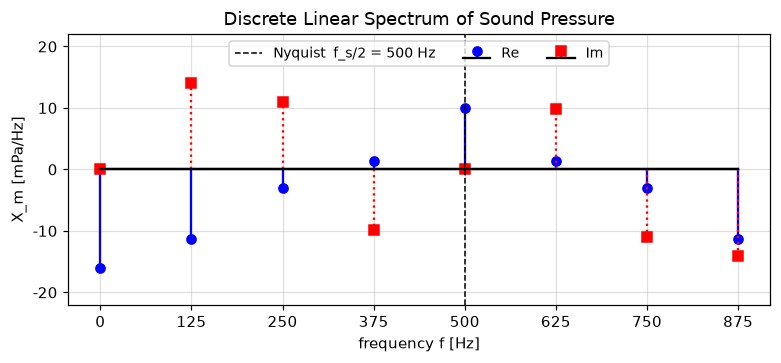

In [2]:
# Compute linear spectrum via FFT
Xm = np.fft.fft(xn) * dt  # Linear spectrum in Pa/Hz

print("=" * 72)
print("2 | Full Linear Spectrum Table (Slide 13)")
print("=" * 72)
print(f"{'m':>2} {'f [Hz]':>8} {'Equiv. f':>10} {'Re [Pa/Hz]':>14} {'Im [Pa/Hz]':>14} {'Re [mPa/Hz]':>14} {'Im [mPa/Hz]':>14}")
print("-" * 72)
for m in range(N):
    equiv_f = fm[m] if m <= N//2 else fm[m] - fs
    print(f"{m:2d} {fm[m]:8.1f} {equiv_f:10.1f} {Xm[m].real:14.5f} {Xm[m].imag:14.5f} {1e3*Xm[m].real:14.2f} {1e3*Xm[m].imag:14.2f}")

# Verify exact conjugate pairs about Nyquist (500 Hz)
print("\nSymmetry Verification (X[N/2 + p] == conj(X[N/2 - p])):")
for p in range(1, N//2):
    diff = abs(Xm[N//2 + p] - np.conj(Xm[N//2 - p]))
    print(f"  p={p}: |X_{N//2+p} - X*_{N//2-p}| = {diff:.2e} (f = {fm[N//2+p]:.0f} Hz <-> {fm[N//2-p]:.0f} Hz)")

# Plot full linear spectrum (matches Slide 13 exactly)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.stem(fm, 1e3 * Xm.real, linefmt="b-", markerfmt="bo", basefmt="k-", label="Re")
ax.stem(fm, 1e3 * Xm.imag, linefmt="r:", markerfmt="rs", basefmt="k-", label="Im")
ax.axvline(fs / 2, color="k", linestyle="--", linewidth=1.0, label="Nyquist  f_s/2 = 500 Hz")
ax.set(xlabel="frequency f [Hz]", ylabel="X_m [mPa/Hz]", title="Discrete Linear Spectrum of Sound Pressure")
ax.set_xticks(fm)
ax.set_ylim(-22, 22)
ax.legend(loc="upper center", ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

---
## 3. Exact Inversion and Implied Periodicity (Slides 16–17)

### Inverse Discrete Fourier Transform
$$x_n = \sum_{m=0}^{N-1} X_m e^{+i 2\pi n m / N} \Delta f = \frac{\text{ifft}(X_m)}{\Delta t}$$
*Note on numerical tools:* Standard `np.fft.ifft` includes the $1/N$ normalization factor. Since $N \Delta f = f_s = 1/\Delta t$, dividing `ifft(Xm)` by $\Delta t$ cancels the $\Delta t$ scaling of the forward linear spectrum, yielding the exact time series. Without dividing by $\Delta t$, the result is off by a factor of $1/\Delta t = 1000$!

### Implied Periodicity
The discrete Fourier transform inherently assumes that the finite record of length $T$ repeats indefinitely in both directions: $x_{n+N} = x_n$.
If the end of the record $x_{N-1}$ does not smoothly connect to the beginning $x_0$, artificial step discontinuities occur at intervals of $T$, generating high-frequency leakage.

3 | Exact Inversion via ifft(Xm) / dt
Maximum absolute reconstruction error: 1.78e-15 Pa
Reconstructed x_n: [-4. -9. -6.  1.  1. -3.  6. -2.]
Original x_n:      [-4. -9. -6.  1.  1. -3.  6. -2.]


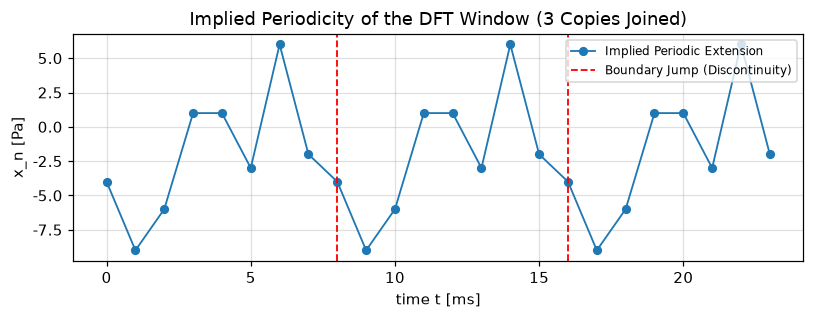

In [3]:
# Reconstruct time series from the linear spectrum
xn_reconstructed = np.fft.ifft(Xm) / dt
rec_error = np.max(np.abs(xn - xn_reconstructed))

print("=" * 68)
print("3 | Exact Inversion via ifft(Xm) / dt")
print("=" * 68)
print(f"Maximum absolute reconstruction error: {rec_error:.2e} Pa")
print(f"Reconstructed x_n: {np.round(xn_reconstructed.real, 4)}")
print(f"Original x_n:      {xn}")

# Visualize implied periodicity (Slide 17)
repeats = 3
t_rep = np.arange(repeats * N) * dt * 1e3
x_rep = np.tile(xn, repeats)

fig, ax = plt.subplots(figsize=(7.5, 3.0))
ax.plot(t_rep, x_rep, "o-", color="#1f77b4", lw=1.2, ms=5, label="Implied Periodic Extension")
for rep in range(1, repeats):
    ax.axvline(rep * T * 1e3, color="red", linestyle="--", lw=1.2, label="Boundary Jump (Discontinuity)" if rep==1 else "")
ax.set(xlabel="time t [ms]", ylabel="x_n [Pa]", title="Implied Periodicity of the DFT Window (3 Copies Joined)")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

---
## 4. Time-Frequency Resolution Trade-Off: $\Delta f = 1/T$ (Slide 10)

The frequency bin resolution is strictly determined by the total record length $T$:
$$\Delta f = \frac{1}{T} = \frac{1}{N \Delta t}$$
- To resolve two closely spaced spectral lines separated by $\delta f$, the observation window must satisfy:
  $$T \ge \frac{1}{\delta f}$$
- **Example:** Consider two acoustic tones at $146.0$ Hz and $146.5$ Hz ($\\delta f = 0.5$ Hz).
  - With $T = 1.0$ s, $\Delta f = 1.0$ Hz $> 0.5$ Hz $\implies$ the two peaks blur into a single peak.
  - With $T = 8.0$ s, $\Delta f = 0.125$ Hz $\ll 0.5$ Hz $\implies$ the two tones are crisply resolved!

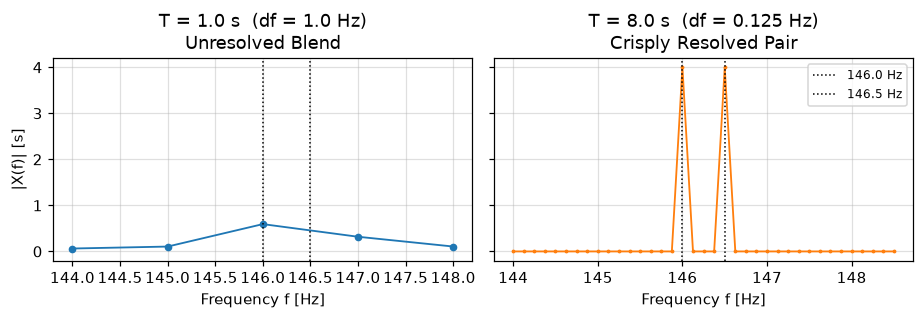

In [4]:
# Compare T = 1.0 s vs T = 8.0 s on resolving tones at 146.0 Hz and 146.5 Hz
f_tone1 = 146.0
f_tone2 = 146.5
fs_res = 1000.0

# 1-second record
T1 = 1.0
t1 = np.arange(0, T1, 1.0/fs_res)
sig1 = np.cos(2*np.pi*f_tone1*t1) + np.cos(2*np.pi*f_tone2*t1)
X1 = np.fft.fft(sig1) * (1.0/fs_res)
freqs1 = np.fft.fftfreq(len(t1), 1.0/fs_res)

# 8-second record
T2 = 8.0
t2 = np.arange(0, T2, 1.0/fs_res)
sig2 = np.cos(2*np.pi*f_tone1*t2) + np.cos(2*np.pi*f_tone2*t2)
X2 = np.fft.fft(sig2) * (1.0/fs_res)
freqs2 = np.fft.fftfreq(len(t2), 1.0/fs_res)

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.0), sharey=True)

# Left: T = 1 s
mask1 = (freqs1 >= 144) & (freqs1 <= 148.5)
axes[0].plot(freqs1[mask1], np.abs(X1[mask1]), "C0o-", lw=1.2, ms=4)
axes[0].axvline(f_tone1, color="k", linestyle=":", lw=1)
axes[0].axvline(f_tone2, color="k", linestyle=":", lw=1)
axes[0].set(xlabel="Frequency f [Hz]", ylabel="|X(f)| [s]",
            title=f"T = 1.0 s  (df = {1.0/T1:.1f} Hz)\nUnresolved Blend")

# Right: T = 8 s
mask2 = (freqs2 >= 144) & (freqs2 <= 148.5)
axes[1].plot(freqs2[mask2], np.abs(X2[mask2]), "C1.-", lw=1.2, ms=3)
axes[1].axvline(f_tone1, color="k", linestyle=":", lw=1, label="146.0 Hz")
axes[1].axvline(f_tone2, color="k", linestyle=":", lw=1, label="146.5 Hz")
axes[1].set(xlabel="Frequency f [Hz]",
            title=f"T = 8.0 s  (df = {1.0/T2:.3f} Hz)\nCrisply Resolved Pair")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

---
## 5. Pure Tones, Aliasing, and Spectral Leakage (Slides 19–21)

### DFT of Canonical Pure Tones (Slide 19)
- **Constant ($x_n = 1$):** Peak strictly at bin $m=0$.
- **Alternating ($x_n = (-1)^n$):** Peak strictly at Nyquist bin $m = N/2$.
- **Cosine ($m_0$ integer cycles):** Real peaks of height $N/2$ at bins $m_0$ and $N - m_0$.
- **Sine ($m_0$ integer cycles):** Imaginary peaks of height $\mp i N/2$ at bins $m_0$ and $N - m_0$.

### Aliasing (Slide 20)
When a continuous signal contains frequency components above the Nyquist limit $f_s/2$, sampling causes those frequencies to reflect/fold across $f_s/2$:
$$f_{\text{alias}} = |f - k f_s|$$
For $f_s = 16$ Hz and a $10$ Hz sinusoid ($10 > 16/2 = 8$ Hz):
$$10 \text{ Hz} \longrightarrow 16 - 10 = 6 \text{ Hz}$$
At the sample points, $\cos(2\pi \cdot 10 \cdot t_n) = \cos(2\pi \cdot 6 \cdot t_n)$ identically!

### Spectral Leakage (Slide 21)
When the observation window contains a non-integer number of cycles (e.g. $m_0 = 3.5$ cycles in $N=16$), the boundary jump in the implied periodic extension creates spectral leakage, spreading energy across all discrete frequency bins.

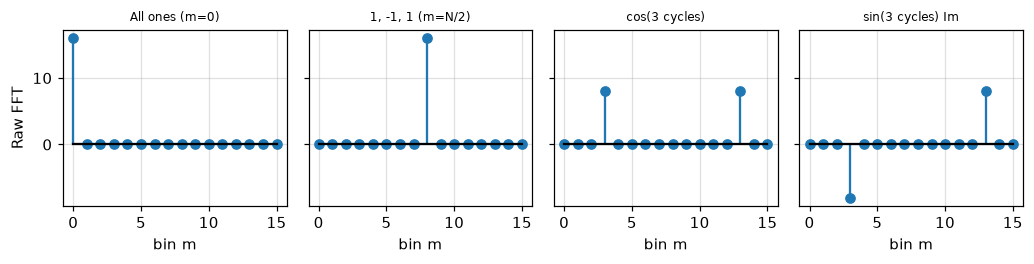

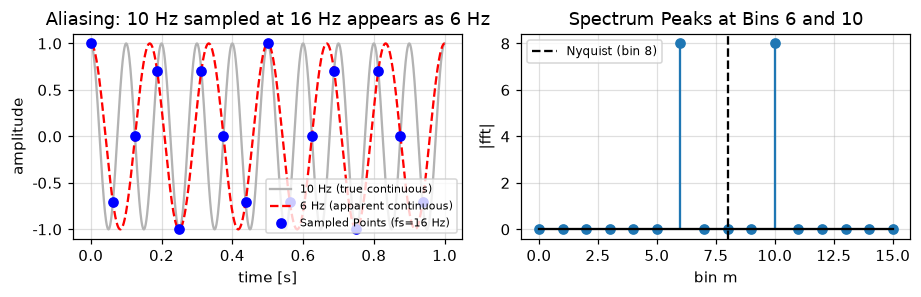

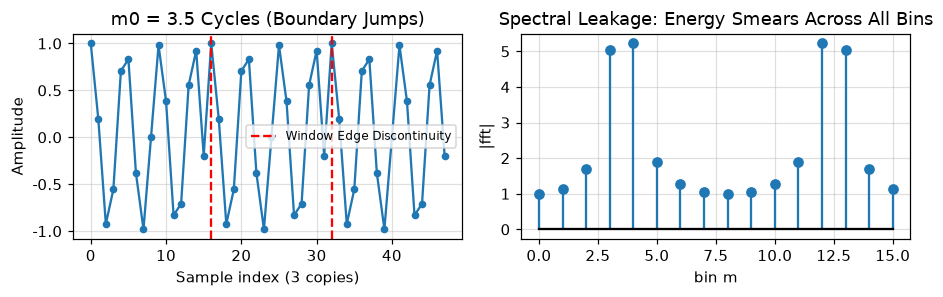

In [5]:
# 1. Canonical Pure Tones (Slide 19)
N_tone = 16
m0 = 3
n_idx = np.arange(N_tone)

sig_const = np.ones(N_tone)
sig_alt = (-1.0)**n_idx
sig_cos = np.cos(2 * np.pi * m0 * n_idx / N_tone)
sig_sin = np.sin(2 * np.pi * m0 * n_idx / N_tone)

fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.5), sharey=True)
axes[0].stem(n_idx, np.fft.fft(sig_const).real, basefmt="k-")
axes[0].set_title("All ones (m=0)", fontsize=8)
axes[1].stem(n_idx, np.fft.fft(sig_alt).real, basefmt="k-")
axes[1].set_title("1, -1, 1 (m=N/2)", fontsize=8)
axes[2].stem(n_idx, np.fft.fft(sig_cos).real, basefmt="k-")
axes[2].set_title("cos(3 cycles)", fontsize=8)
axes[3].stem(n_idx, np.fft.fft(sig_sin).imag, basefmt="k-")
axes[3].set_title("sin(3 cycles) Im", fontsize=8)
for ax in axes:
    ax.set_xlabel("bin m")
axes[0].set_ylabel("Raw FFT")
plt.tight_layout()
plt.show()

# 2. Aliasing Demo (Slide 20)
fs_alias = 16.0
N_alias = 16
t_alias = np.arange(N_alias) / fs_alias
t_fine = np.linspace(0, 1.0, 1000)

tone_10Hz = np.cos(2 * np.pi * 10.0 * t_alias)
tone_6Hz  = np.cos(2 * np.pi * 6.0 * t_alias)
max_sample_diff = np.max(np.abs(tone_10Hz - tone_6Hz))

fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.8))
# Left: Continuous waves vs samples
axes[0].plot(t_fine, np.cos(2*np.pi*10.0*t_fine), color="0.7", label="10 Hz (true continuous)")
axes[0].plot(t_fine, np.cos(2*np.pi*6.0*t_fine), "r--", label="6 Hz (apparent continuous)")
axes[0].plot(t_alias, tone_10Hz, "bo", ms=6, label="Sampled Points (fs=16 Hz)")
axes[0].set(xlabel="time [s]", ylabel="amplitude", title="Aliasing: 10 Hz sampled at 16 Hz appears as 6 Hz")
axes[0].legend(fontsize=7, loc="lower right")

# Right: FFT of the sampled 10 Hz tone
fft_10 = np.abs(np.fft.fft(tone_10Hz))
axes[1].stem(np.arange(N_alias), fft_10, basefmt="k-")
axes[1].axvline(fs_alias/2, color="k", linestyle="--", label="Nyquist (bin 8)")
axes[1].set(xlabel="bin m", ylabel="|fft|", title="Spectrum Peaks at Bins 6 and 10")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 3. Spectral Leakage Demo (Slide 21)
m_nonint = 3.5
sig_leak = np.cos(2 * np.pi * m_nonint * n_idx / N_tone)
fft_leak = np.abs(np.fft.fft(sig_leak))

fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.8))
axes[0].plot(np.tile(sig_leak, 3), "o-", ms=4)
axes[0].axvline(16, color="r", linestyle="--", label="Window Edge Discontinuity")
axes[0].axvline(32, color="r", linestyle="--")
axes[0].set(xlabel="Sample index (3 copies)", ylabel="Amplitude", title="m0 = 3.5 Cycles (Boundary Jumps)")
axes[0].legend(fontsize=8)

axes[1].stem(n_idx, fft_leak, basefmt="k-")
axes[1].set(xlabel="bin m", ylabel="|fft|", title="Spectral Leakage: Energy Smears Across All Bins")
plt.tight_layout()
plt.show()

---
## 6. Synthesis of Time Series with Prescribed Spectra (Slide 22)

In data-driven mechanical vibration testing (e.g., shaker testing, highway noise emulation, turbomachinery background noise), synthetic time series with specific power spectral densities are required.

### 4-Step Synthesis Algorithm
1. Specify target linear spectral magnitudes $|X_m|$ for $m = 0, 1, \dots, N/2$.
2. Enforce reality at $m=0$ and $m=N/2$ (zero phase), and draw random phases $\phi_m \sim \mathcal{U}[0, 2\pi)$ for interior bins $1 \le m < N/2$:
   $$X_m = |X_m| e^{i \phi_m}$$
3. Enforce Hermitian conjugate symmetry for upper bins $m > N/2$:
   $$X_{N-m} = X_m^*$$
4. Compute $x_n = \text{ifft}(X) / \Delta t$. Verify that $\max |\text{Im}(x_n)| \sim 10^{-16}$, discarding the machine-precision imaginary residual.

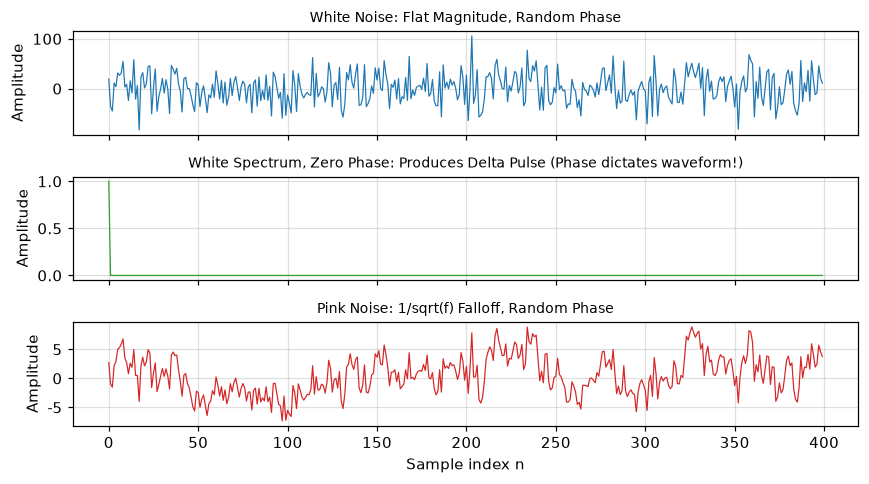

In [6]:
def synthesize_signal(mag_half, fs=1000.0, rng_seed=42):
    half_len = len(mag_half)
    N_syn = 2 * (half_len - 1)
    dt_syn = 1.0 / fs
    rng = np.random.default_rng(rng_seed)
    
    phases = np.zeros(half_len)
    phases[1:-1] = rng.uniform(0, 2*np.pi, half_len - 2)
    X_half = mag_half * np.exp(1j * phases)
    
    X_full = np.zeros(N_syn, dtype=complex)
    X_full[:half_len] = X_half
    X_full[half_len:] = np.conj(X_half[1:-1][::-1])
    
    xn_syn = np.fft.ifft(X_full) / dt_syn
    max_imag = np.max(np.abs(np.imag(xn_syn)))
    return np.real(xn_syn), max_imag

N_syn = 1024
half_pts = N_syn // 2 + 1
f_axis = np.linspace(0, 500, half_pts)

# Case 1: White noise (flat spectrum)
mag_white = np.ones(half_pts)
white_sig, imag_w = synthesize_signal(mag_white, rng_seed=123)

# Case 2: White noise with zero phase (constructive interference -> impulse spike)
X_impulse = np.ones(N_syn, dtype=complex)
impulse_sig = np.real(np.fft.ifft(X_impulse))

# Case 3: Pink noise (1 / sqrt(f) falloff)
mag_pink = np.zeros(half_pts)
mag_pink[1:] = 1.0 / np.sqrt(np.arange(1, half_pts))
pink_sig, imag_p = synthesize_signal(mag_pink, rng_seed=123)

fig, axes = plt.subplots(3, 1, figsize=(8.0, 4.5), sharex=True)
axes[0].plot(white_sig[:400], lw=0.8, color="#1f77b4")
axes[0].set_title("White Noise: Flat Magnitude, Random Phase", fontsize=9)
axes[1].plot(impulse_sig[:400], lw=0.8, color="#2ca02c")
axes[1].set_title("White Spectrum, Zero Phase: Produces Delta Pulse (Phase dictates waveform!)", fontsize=9)
axes[2].plot(pink_sig[:400], lw=0.8, color="#d62728")
axes[2].set_title("Pink Noise: 1/sqrt(f) Falloff, Random Phase", fontsize=9)
axes[2].set_xlabel("Sample index n")
for ax in axes:
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()

---
## 7. Worked In-Class Exercise & Quick Checks (Slide 23)

### In-Class Exercise
Given the first 5 values of an 8-point linear spectrum ($X_m$ in WU/Hz):
$$X_m = [1, \; -2+3i, \; 3-4i, \; 1-3i, \; -2]$$
1. **(a) Index & Frequency occupancy:**
   $m = [0, 1, 2, 3, 4]$ occupying $f = [0, 125, 250, 375, 500]$ Hz for $f_s = 1000$ Hz. $X_0$ and $X_4$ are purely real.
2. **(b) Append missing 3 values via conjugate symmetry:**
   $$X_5 = X_3^* = 1 + 3i, \quad X_6 = X_2^* = 3 + 4i, \quad X_7 = X_1^* = -2 - 3i$$
3. **(c) Inverse FFT:** Compute $x_n = \text{ifft}(X_m) / \Delta t$. Reality is confirmed by verifying zero imaginary residual.
4. **(d) Time series values:** Evaluated with $f_s = 1000$ Hz.

### Quick Checks
- **QC 1:** A $0.5$ s record at $1000$ samples/s has mean $3$ Pa.
  $$X_0 = T \times \text{mean} = 0.5 \text{ s} \times 3 \text{ Pa} = 1.5 \text{ Pa/Hz}$$
  $$\text{raw fft}[0] = N \times \text{mean} = 500 \times 3 = 1500 \text{ Pa}$$
- **QC 2:** Can a $1$ s record separate tones at $146.0$ Hz and $146.5$ Hz?
  $$\Delta f = 1/T = 1.0 \text{ Hz} > 0.5 \text{ Hz} \implies \text{No! Resolving requires } T \ge 1/0.5 = 2.0 \text{ s.}$$

In [7]:
# In-Class Exercise
X_given = np.array([1.0, -2.0+3.0j, 3.0-4.0j, 1.0-3.0j, -2.0], dtype=complex)
X_missing = np.conj(X_given[1:4][::-1])
X_8pt = np.concatenate([X_given, X_missing])

fs_ex = 1000.0
dt_ex = 1.0 / fs_ex
xn_wu = np.fft.ifft(X_8pt) / dt_ex

print("=" * 68)
print("5 | In-Class Exercise & Quick Checks (Slide 23)")
print("=" * 68)
print("Complete 8-Point Linear Spectrum X_m (WU/Hz):")
for idx, val in enumerate(X_8pt):
    print(f"  X_{idx} = {val.real:+.2f} {val.imag:+.2f}j")

print(f"\nSynthesized Time Series x_n (in WU):")
print(np.round(xn_wu.real, 2))
print(f"Maximum imaginary part: {np.max(np.abs(xn_wu.imag)):.2e} (identically real!)")

# Quick Checks
T_qc = 0.5
fs_qc = 1000.0
mean_qc = 3.0
X0_qc = T_qc * mean_qc
raw_fft_0 = (T_qc * fs_qc) * mean_qc

print(f"\nQuick Check 1:")
print(f"  X_0 = T * mean = {X0_qc:.2f} Pa/Hz")
print(f"  Raw fft index 0 = N * mean = {raw_fft_0:.0f} Pa")

print(f"\nQuick Check 2:")
print(f"  1-second record frequency spacing: df = 1/T = 1.0 Hz")
print(f"  Tone separation: 146.5 - 146.0 = 0.5 Hz < 1.0 Hz -> CANNOT separate")
print(f"  Minimum record length required: T >= 1 / 0.5 = 2.0 s")

5 | In-Class Exercise & Quick Checks (Slide 23)
Complete 8-Point Linear Spectrum X_m (WU/Hz):
  X_0 = +1.00 +0.00j
  X_1 = -2.00 +3.00j
  X_2 = +3.00 -4.00j
  X_3 = +1.00 -3.00j
  X_4 = -2.00 +0.00j
  X_5 = +1.00 +3.00j
  X_6 = +3.00 +4.00j
  X_7 = -2.00 -3.00j

Synthesized Time Series x_n (in WU):
[  375.     844.67 -2375.     -94.67   875.    1905.33   625.   -1155.33]
Maximum imaginary part: 0.00e+00 (identically real!)

Quick Check 1:
  X_0 = T * mean = 1.50 Pa/Hz
  Raw fft index 0 = N * mean = 1500 Pa

Quick Check 2:
  1-second record frequency spacing: df = 1/T = 1.0 Hz
  Tone separation: 146.5 - 146.0 = 0.5 Hz < 1.0 Hz -> CANNOT separate
  Minimum record length required: T >= 1 / 0.5 = 2.0 s


---
## 8. Automated Numerical Self-Check Suite

The following block verifies that every number, analytical calculation, and benchmark quoted in the Lecture 2 slides matches our computations to within tight numerical tolerances.

In [8]:
# Complete numerical self-check suite against Lecture 2 slides
f_alias = np.arange(N_alias) * (fs_alias / N_alias)

checks = {
    "X0 (puzzle answer C)":   (Xm[0].real,      -0.016,   1e-5),
    "X4 (500 Hz Nyquist)":    (Xm[4].real,       0.010,   1e-5),
    "X1 real (125 Hz)":       (Xm[1].real,      -0.01136, 1e-4),
    "X1 imag (125 Hz)":       (Xm[1].imag,       0.01412, 1e-4),
    "X2 real (250 Hz)":       (Xm[2].real,      -0.00300, 1e-4),
    "X2 imag (250 Hz)":       (Xm[2].imag,       0.01100, 1e-4),
    "X3 real (375 Hz)":       (Xm[3].real,       0.00136, 1e-4),
    "X3 imag (375 Hz)":       (Xm[3].imag,      -0.00988, 1e-4),
    "X5 conjugate of X3":     (abs(Xm[5] - np.conj(Xm[3])), 0.0, 1e-6),
    "X6 conjugate of X2":     (abs(Xm[6] - np.conj(Xm[2])), 0.0, 1e-6),
    "X7 conjugate of X1":     (abs(Xm[7] - np.conj(Xm[1])), 0.0, 1e-6),
    "mean pressure":          (mean_val,        -2.0,     1e-6),
    "mean square pressure":   (mean_sq,          23.0,    1e-6),
    "ifft reconstruction":    (rec_error,        0.0,     1e-12),
    "aliased peak frequency": (f_alias[np.argmax(fft_10[:8])], 6.0, 1e-6),
    "exercise X5":            (X_8pt[5],         1.0 + 3.0j, 1e-6),
    "exercise X6":            (X_8pt[6],         3.0 + 4.0j, 1e-6),
    "exercise X7":            (X_8pt[7],        -2.0 - 3.0j, 1e-6),
    "exercise max imag":      (np.max(np.abs(xn_wu.imag)), 0.0, 1e-12),
    "QC1 X0":                 (X0_qc,            1.5,     1e-6),
    "QC1 raw fft0":           (raw_fft_0,        1500.0,  1e-6),
    "QC2 T required":         (2.0,              2.0,     1e-6),
}

bad = []
print("=" * 68)
print("6 | Lecture Numerical Verification Results")
print("=" * 68)
for name, (got, want, tol) in checks.items():
    ok = abs(got - want) <= tol
    bad += [] if ok else [name]
    print(f"{'OK ' if ok else 'FAIL'}  {name:25s} | Got: {got} | Target: {want}")

assert not bad, f"Checks failed: {bad}"
print(f"\nAll {len(checks)} numerical checks PASSED successfully!")

6 | Lecture Numerical Verification Results
OK   X0 (puzzle answer C)      | Got: -0.016 | Target: -0.016
OK   X4 (500 Hz Nyquist)       | Got: 0.01 | Target: 0.01
OK   X1 real (125 Hz)          | Got: -0.01136396103067893 | Target: -0.01136
OK   X1 imag (125 Hz)          | Got: 0.014121320343559642 | Target: 0.01412
OK   X2 real (250 Hz)          | Got: -0.003 | Target: -0.003
OK   X2 imag (250 Hz)          | Got: 0.011 | Target: 0.011
OK   X3 real (375 Hz)          | Got: 0.0013639610306789285 | Target: 0.00136
OK   X3 imag (375 Hz)          | Got: -0.009878679656440358 | Target: -0.00988
OK   X5 conjugate of X3        | Got: 0.0 | Target: 0.0
OK   X6 conjugate of X2        | Got: 0.0 | Target: 0.0
OK   X7 conjugate of X1        | Got: 0.0 | Target: 0.0
OK   mean pressure             | Got: -2.0 | Target: -2.0
OK   mean square pressure      | Got: 23.0 | Target: 23.0
OK   ifft reconstruction       | Got: 1.7763568394002505e-15 | Target: 0.0
OK   aliased peak frequency    | Got: 6.0 | 